# BreastDCEDL
## BreastDCEDL Data load and Visualize



In [1]:
from sklearn.metrics import classification_report,auc,roc_auc_score
from PIL import Image
import time
from pathlib import Path


import os
import numpy as np
import pandas as pd
from PIL import Image


import warnings
warnings.filterwarnings('ignore', '.*do not.*', )
warnings.warn('Do not show this message')

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from glob import glob
#from skimage import io
from sklearn.utils import shuffle

#from nipype.interfaces.ants import N4BiasFieldCorrection
import sys
import os
import ast

import warnings
warnings.filterwarnings('ignore')

In [2]:
git_samples = True
base_path = '.'

## Setup path's to git samples

In [4]:

# Set up path's for dce data and mask data
nifti_path= {'spy2':os.path.join(base_path,"ISPY2","data_samples","dce"),
            'spy1':os.path.join(base_path,"ISPY1","data_samples","dce"),
            'duke':os.path.join(base_path,"DUKE","data_samples","dce")}

mask_path={'spy2':os.path.join(base_path,"ISPY2","data_samples","mask"),
            'spy1':os.path.join(base_path,"ISPY1","data_samples","mask"),
            'duke':os.path.join(base_path,"DUKE","data_samples","mask")}



# Load and view metada

In [5]:
df=pd.read_csv('BreastDCEDL_metadata.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2070 entries, 0 to 2069
Data columns (total 29 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   pid             2070 non-null   object 
 1   pCR             1452 non-null   float64
 2   n_xy            2070 non-null   float64
 3   n_z             2070 non-null   float64
 4   n_times         2070 non-null   float64
 5   pre             2070 non-null   float64
 6   post_early      2070 non-null   float64
 7   post_late       2070 non-null   float64
 8   slice_thick     2070 non-null   float64
 9   xy_spacing      2070 non-null   float64
 10  mask_start      2070 non-null   float64
 11  mask_end        2070 non-null   float64
 12  sraw            2070 non-null   float64
 13  eraw            2070 non-null   float64
 14  scol            2070 non-null   float64
 15  ecol            2070 non-null   float64
 16  tum_vol         1456 non-null   float64
 17  age             2070 non-null   f

In [6]:
df.test.value_counts(dropna=False)

,count
test,
0.0,1531
1.0,271
2.0,268


In [7]:
df.pCR.value_counts(dropna=False)

,count
pCR,
0.0,1024
NaN,618
1.0,428


In [8]:
pd.crosstab(df.test,df.pCR, dropna=False)

pCR,0.0,1.0,NaN
test,,,
0.0,777,322,432
1.0,124,53,94
2.0,123,53,92


In [9]:
pd.crosstab(df.test,df.HR, dropna=False)

HR,0.0,1.0,NaN
test,,,
0.0,542,987,2
1.0,98,173,0
2.0,101,167,0


In [10]:
pd.crosstab(df.test,df.HER2, dropna=False)

HER2,0.0,1.0,NaN
test,,,
0.0,1183,345,3
1.0,213,56,2
2.0,210,58,0


In [11]:
df.columns

Index(['pid', 'pCR', 'n_xy', 'n_z', 'n_times', 'pre', 'post_early',
       'post_late', 'slice_thick', 'xy_spacing', 'mask_start', 'mask_end',
       'sraw', 'eraw', 'scol', 'ecol', 'tum_vol', 'age', 'menopause',
       'race_white', 'race_black', 'HR', 'HER2', 'HR_HER2_STATUS', 'TripleNeg',
       'HER2pos', 'HRposHER2neg', 'dataset', 'test'],
      dtype='object')

# View data examples
## setup path's to DCE and mask data
Add you correct path's to the dictionary in: data_utils.py

In [12]:
import os, sys
sys.path.append(os.path.abspath( 'utils'))

import data_utils as ds

ds.setup_paths(base_path, nifti_path, mask_path)

NIfTI roots : {'spy2': '/content/BreastDCEDL/ISPY2/data_samples/dce', 'spy1': '/content/BreastDCEDL/ISPY1/data_samples/dce', 'duke': '/content/BreastDCEDL/DUKE/data_samples/dce'}
Mask  roots : {'spy2': '/content/BreastDCEDL/ISPY2/data_samples/mask', 'spy1': '/content/BreastDCEDL/ISPY1/data_samples/mask', 'duke': '/content/BreastDCEDL/DUKE/data_samples/mask'}


### Check path's

In [13]:
ds.nifti_path

{'spy2': '/content/BreastDCEDL/ISPY2/data_samples/dce',
 'spy1': '/content/BreastDCEDL/ISPY1/data_samples/dce',
 'duke': '/content/BreastDCEDL/DUKE/data_samples/dce'}

In [14]:
os.listdir(ds.nifti_path['spy1'])

['ISPY1_1072_spy1_vis1_acq0.nii.gz',
 'ISPY1_1072_spy1_vis1_acq2.nii.gz',
 'ISPY1_1072_spy1_vis1_acq1.nii.gz']

In [15]:
os.listdir(ds.mask_path['spy2'])

['ISPY2-550421_spy2_vis1_mask.nii.gz',
 'ACRIN-6698-104268_spy2_vis1_mask.nii.gz',
 'ACRIN-6698-102212_spy2_vis1_mask.nii.gz']

## I-SPY-2 example

In [16]:
df[df.pid.isin(['ACRIN-6698-102212','ISPY2-550421'])]

,pid,pCR,n_xy,n_z,n_times,pre,post_early,post_late,slice_thick,xy_spacing,...,race_white,race_black,HR,HER2,HR_HER2_STATUS,TripleNeg,HER2pos,HRposHER2neg,dataset,test
0,ACRIN-6698-102212,0.0,256.0,80.0,8.0,0.0,2.0,6.0,2.0,0.605500,...,1.0,0.0,0.0,0.0,TripleNeg,1.0,0.0,0.0,spy2,1.0
642,ISPY2-550421,0.0,256.0,160.0,7.0,0.0,2.0,6.0,1.0,0.688073,...,0.0,1.0,0.0,0.0,TripleNeg,1.0,0.0,0.0,spy2,0.0


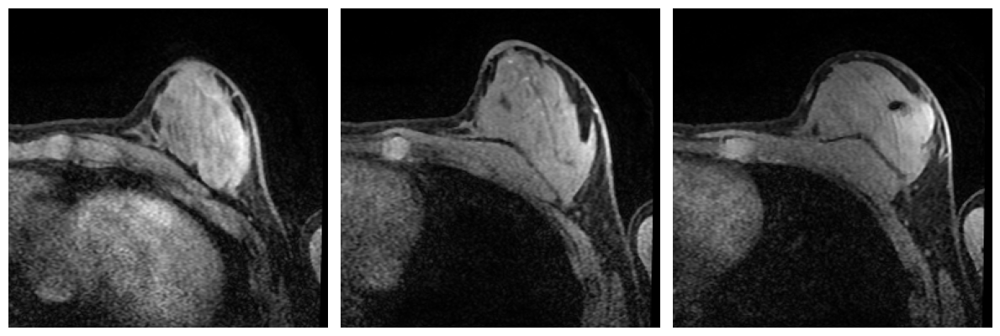

In [17]:

    pid='ACRIN-6698-102212'
    d=ds.get_all_nifti_acquisitions(pid)

    ds.show_n_images([d[0][k] for k in [20,30,40]])




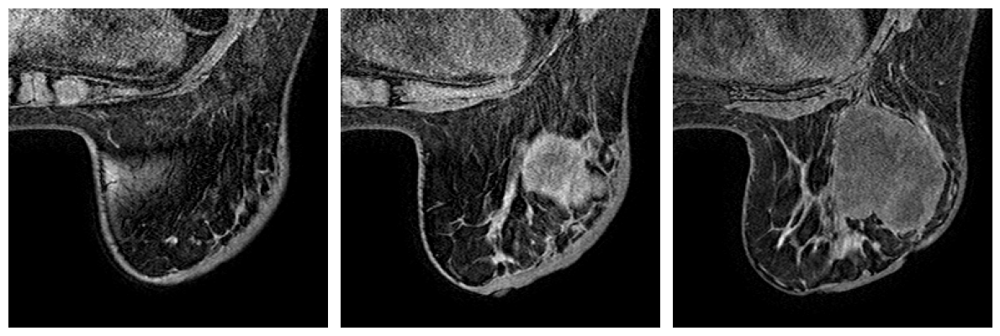

In [18]:
    pid='ISPY2-550421'
    d=ds.get_all_nifti_acquisitions(pid)

    ds.show_n_images([d[0][k] for k in [60,70,90]])



In [19]:
def minmax(imc):
    im=imc.copy()
    if im.max()==0:
        return im
    return (im-im.min())/(im.max()-im.min())

def to_rgb(a,b,c):
    return minmax(np.stack([a,b,c],axis=2))

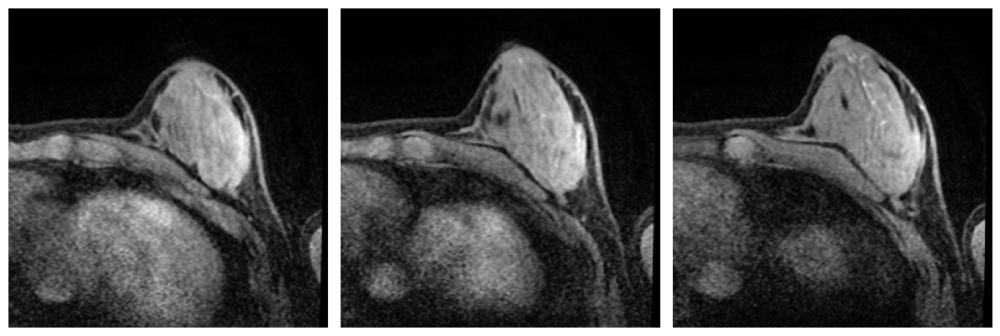

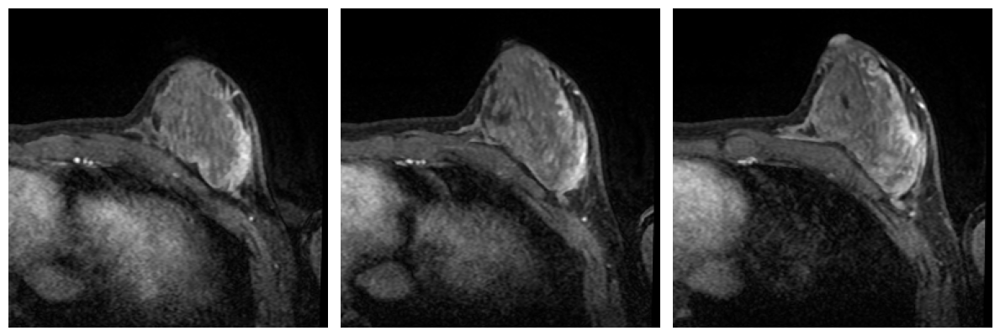

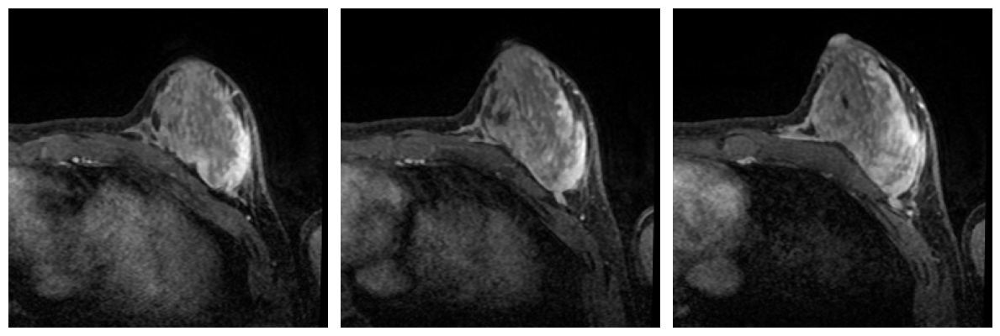

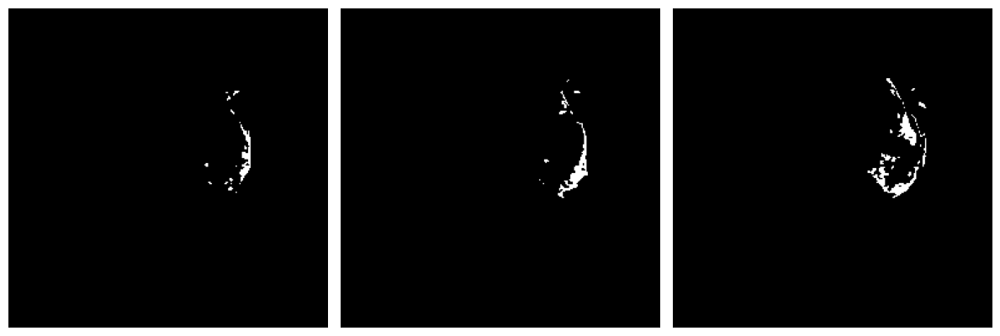

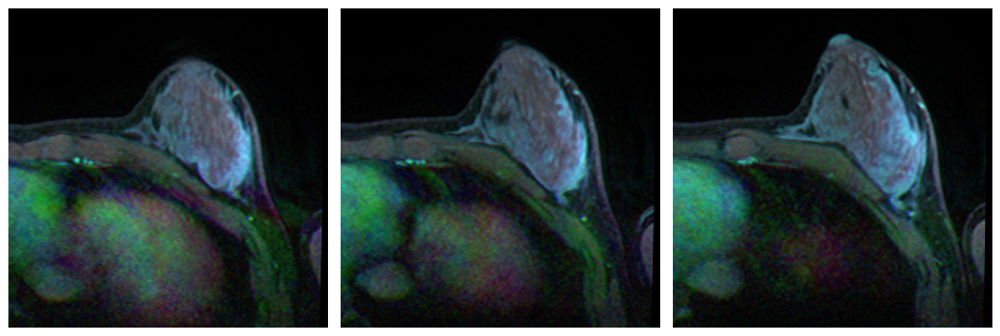

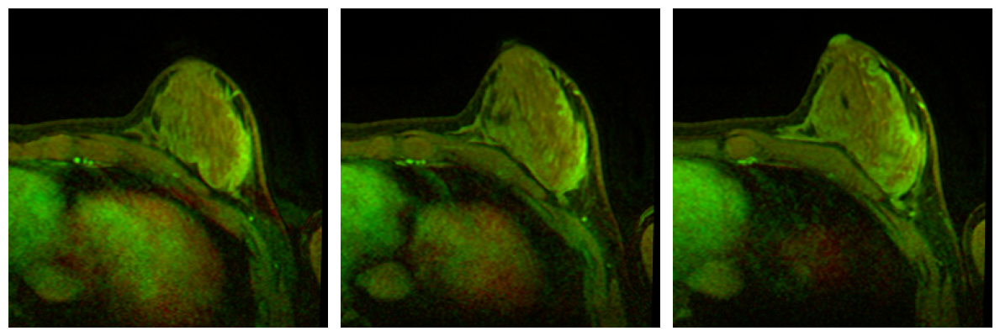

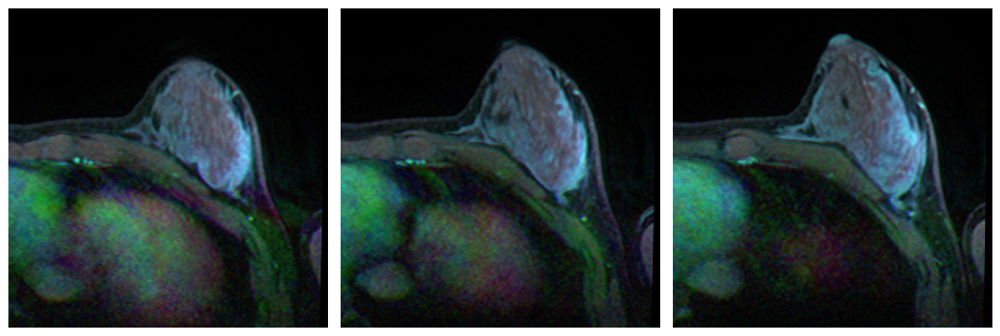

In [20]:

    pid='ACRIN-6698-102212'
    d=ds.get_all_nifti_acquisitions(pid)

    m=ds.get_nifti_mask(pid)
    m.shape

    ds.show_n_images([d[0][k] for k in [20,23,26]],axis_off=True)
    ds.show_n_images([d[1][k] for k in [20,23,26]],axis_off=True)
    ds.show_n_images([d[2][k] for k in [20,23,26]],axis_off=True)
    ds.show_n_images([m[k] for k in [20,23,26]],axis_off=True)

    ds.show_n_images([to_rgb(d[0][k],
                                d[1][k],d[2][k]) for k in [20,23,26]],axis_off=True)
    ds.show_n_images([to_rgb(d[0][k],
                                d[1][k],m[k]) for k in [20,23,26]],axis_off=True)

    ds.show_n_images([to_rgb(d[0][k],
                                d[1][k],d[2][k]) for k in [20,23,26]])



### I-SPY-1 example

In [21]:
pid='ISPY1_1072'
df[df.pid==pid]

,pid,pCR,n_xy,n_z,n_times,pre,post_early,post_late,slice_thick,xy_spacing,...,race_white,race_black,HR,HER2,HR_HER2_STATUS,TripleNeg,HER2pos,HRposHER2neg,dataset,test
1042,ISPY1_1072,0.0,256.0,64.0,3.0,0.0,1.0,2.0,2.0625,0.78125,...,1.0,0.0,0.0,0.0,TripleNeg,1.0,0.0,0.0,spy1,0.0


(64, 256, 256)


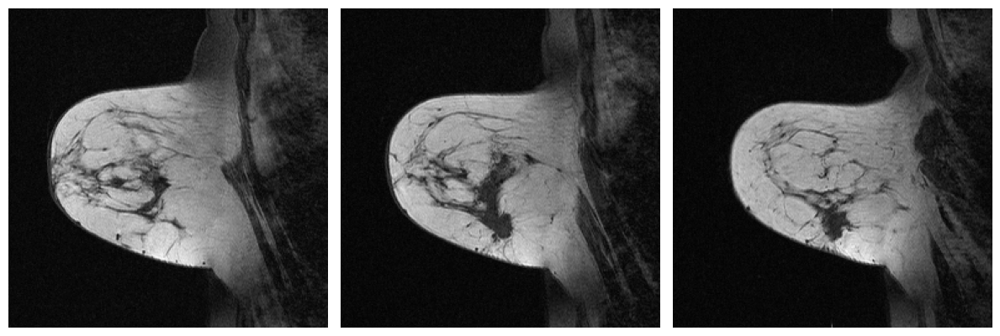

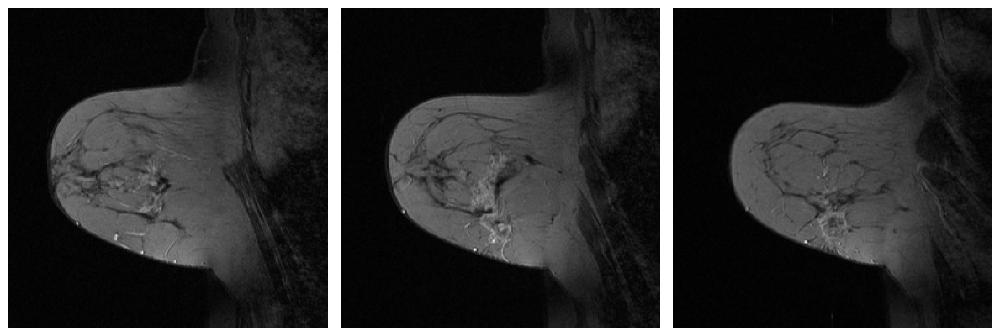

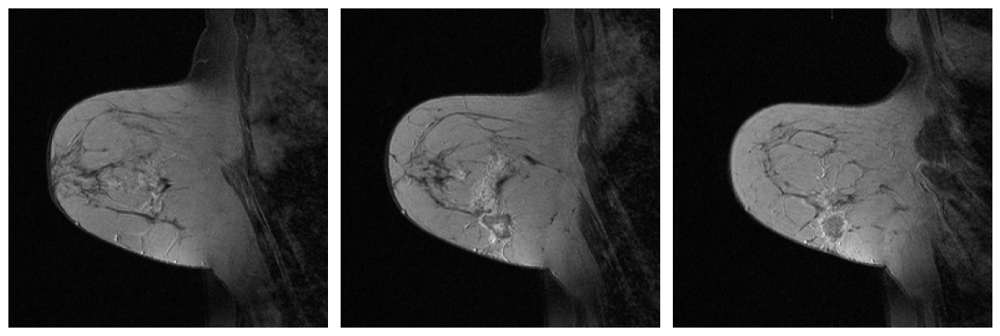

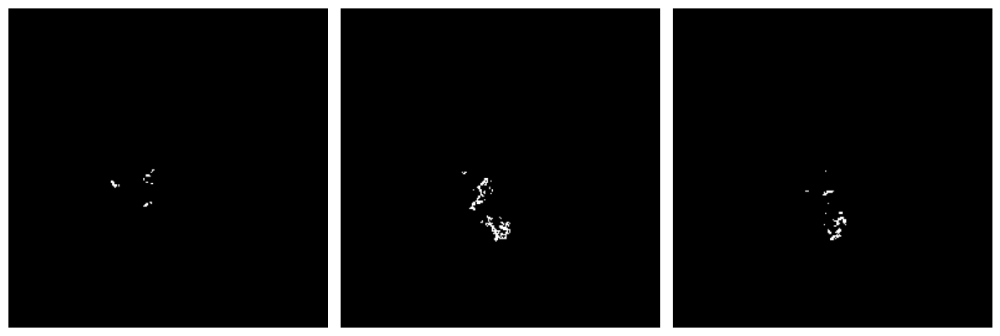

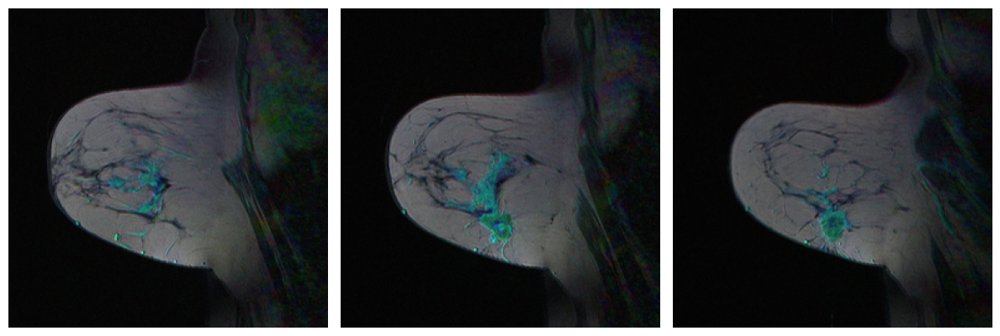

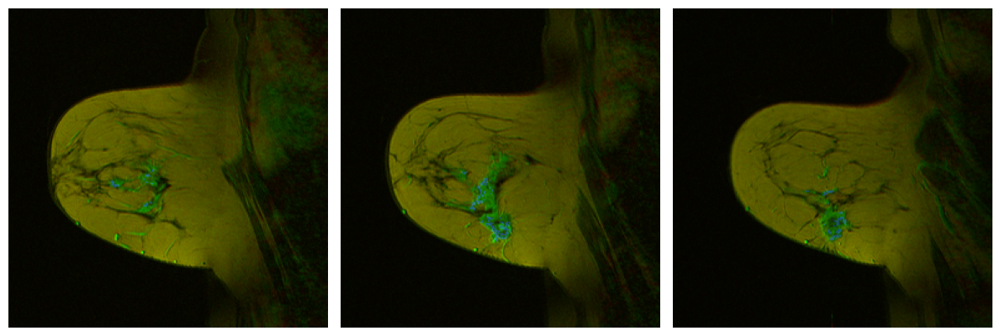

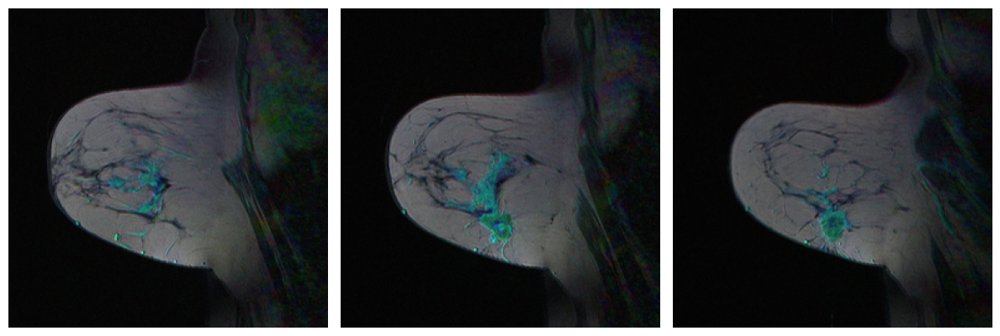

In [22]:
    d=ds.get_all_nifti_acquisitions(pid)

    m=ds.get_nifti_mask(pid)
    print(m.shape)
    idx=[35,40,45]
    ds.show_n_images([d[0][k] for k in idx],axis_off=True)
    ds.show_n_images([d[1][k] for k in idx],axis_off=True)
    ds.show_n_images([d[2][k] for k in idx],axis_off=True)
    ds.show_n_images([m[k] for k in idx],axis_off=True)

    ds.show_n_images([to_rgb(d[0][k],
                                d[1][k],d[2][k]) for k in idx],axis_off=True)
    ds.show_n_images([to_rgb(d[0][k],
                                d[1][k],m[k]) for k in idx],axis_off=True)

    ds.show_n_images([to_rgb(d[0][k],
                                d[1][k],d[2][k]) for k in idx])


### DUKE example

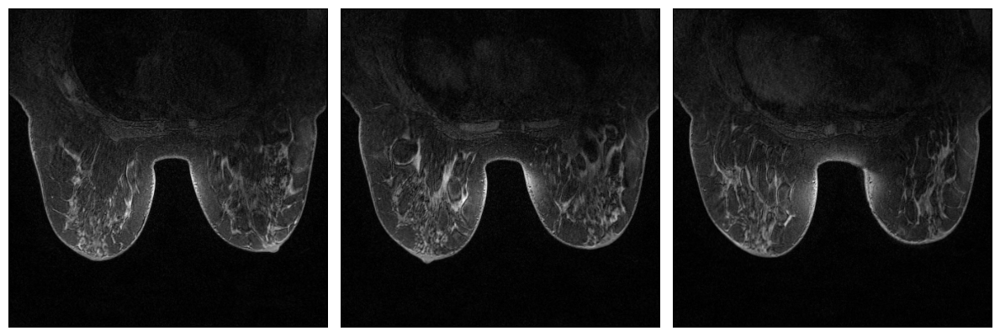

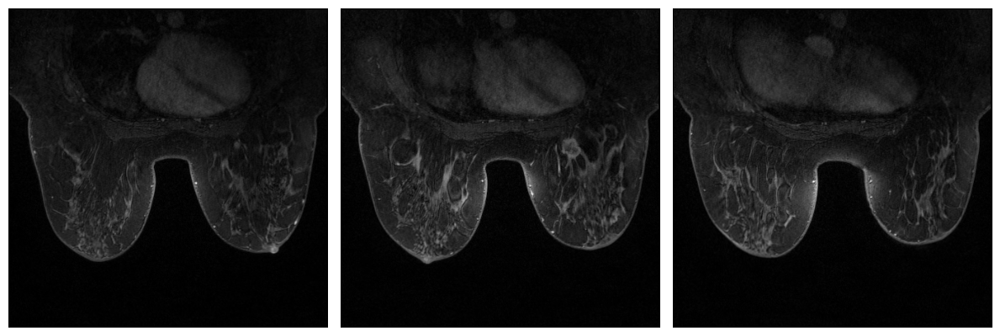

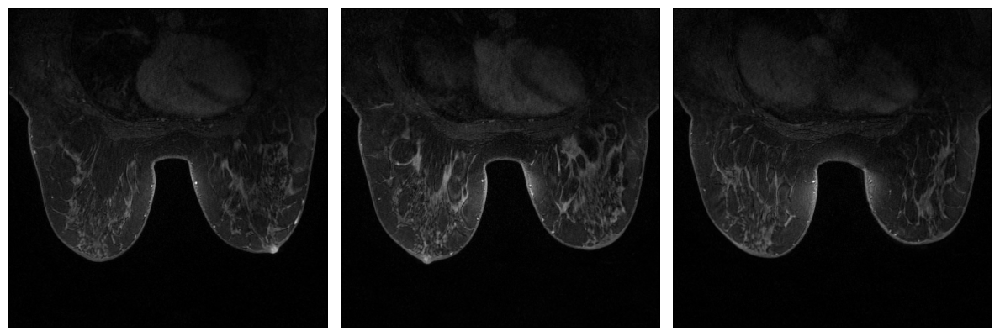

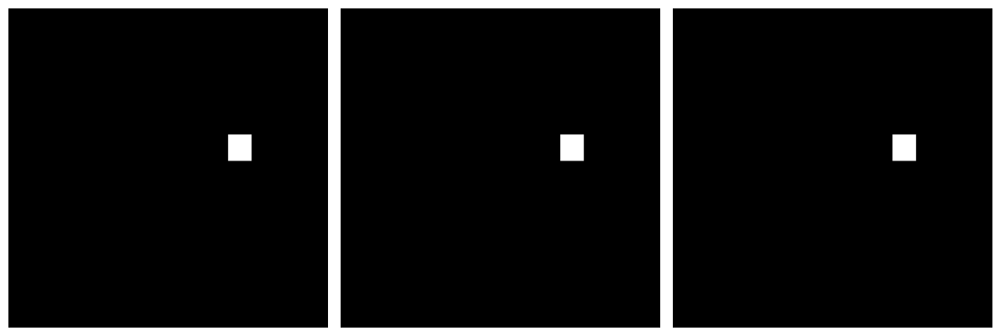

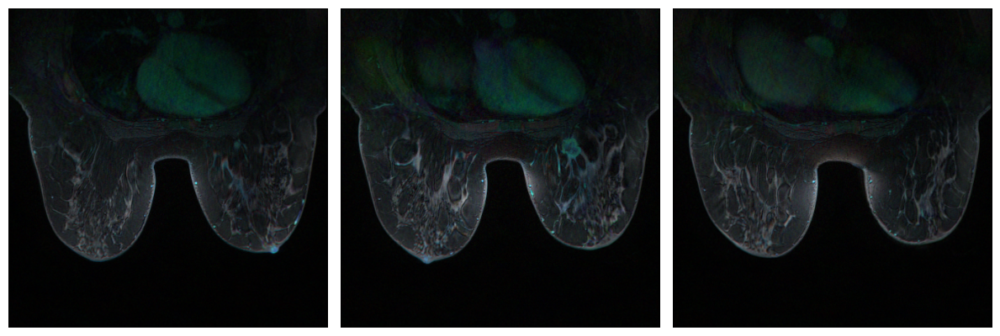

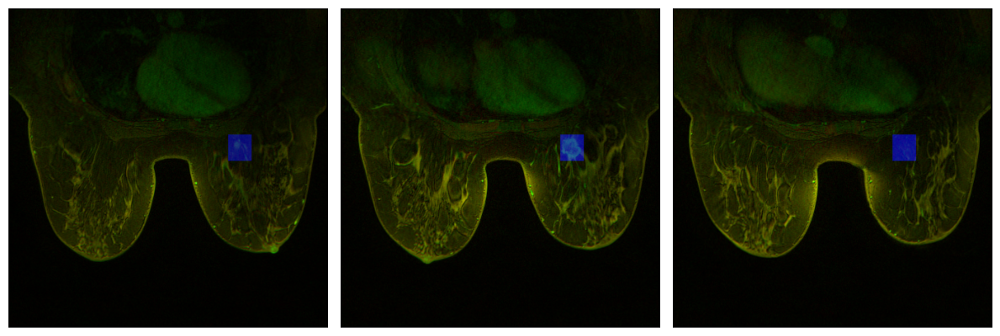

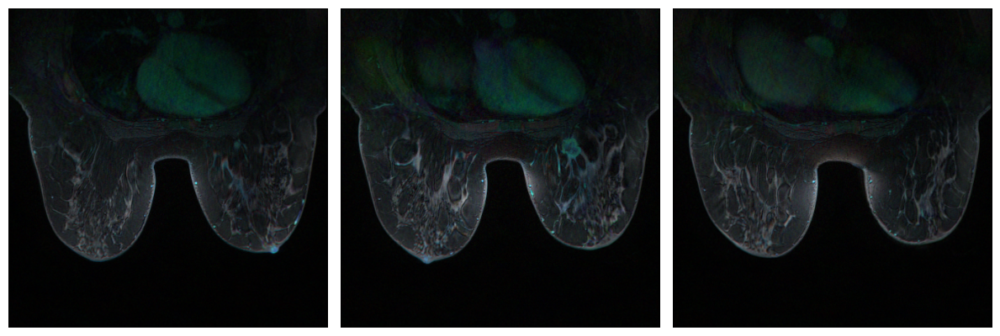

In [23]:
    pid='Breast_MRI_001'
    bbox=df[df.pid==pid][['mask_start', 'mask_end',
           'sraw', 'eraw', 'scol', 'ecol']].values[0]
    d=ds.get_all_nifti_acquisitions(pid)
    m=np.zeros(d[0].shape)
    m[89:112, 234:271, 308:341]=255
    idx=[90,100,110]
    ds.show_n_images([d[0][k] for k in idx],axis_off=True)
    ds.show_n_images([d[1][k] for k in idx],axis_off=True)
    ds.show_n_images([d[2][k] for k in idx],axis_off=True)
    ds.show_n_images([m[k] for k in idx],axis_off=True)

    ds.show_n_images([to_rgb(d[0][k],
                                d[1][k],d[2][k]) for k in idx],axis_off=True)
    ds.show_n_images([to_rgb(d[0][k],
                                d[1][k],m[k]) for k in idx],axis_off=True)

    ds.show_n_images([to_rgb(d[0][k],
                                d[1][k],d[2][k]) for k in idx])
